# ÉquiAlgo: bias audit report (`audit_rapport.ipynb`)

**Question.** The production model grants awards to 48.4% of applicants from Montréal and the
Capitale-Nationale, against 27.3% from Bas-Saint-Laurent, Côte-Nord and Gaspésie–Îles-de-la-Madeleine.
How much of that gap is merit, how much is bias, and where does the bias hide?

**Short answer** (each point is measured below):

1. The R-score difference between the two groups explains about a third of the 21-point gap (7.6 points are left
   if remote applicants are judged like centre applicants with the same R score; we find 13.5 points unexplained by R).
2. The historical committee applies a **flat penalty to remote applicants**: about 2.2 logits,
   worth roughly **1.6 points of R score**. Same size in all three remote regions, absent in both centres,
   constant across the R-score range.
3. The production model learns that penalty. Removing `region_administrative` does not help, because
   **distance, hours worked, postal code and income** predict the region almost perfectly and pick
   the penalty back up.
4. Measured against the historical labels the production model looks almost fair (TPR gap ≈ 0.06).
   Measured against a merit standard without the penalty, its equal-opportunity gap is **≈ 0.26**,
   which matches the 0.270 the organisers report against their hidden reference. That match is our
   main check that the diagnosis is right.
5. There is a **second, quieter channel**: the committee rewards higher family income. Remote families earn
   about 25% less, so this bonus also works against remote applicants. External feedback (HxBuddy indicative
   scores against the hidden reference) confirms that income is not part of merit, while hours worked are
   (section 6).
6. **Where you live changes the decision.** SHAP shows the location columns move the production model's
   probability by about −10 points for remote applicants and +6 for centre applicants, and about one remote
   applicant in eight would be granted an award just by living in Montréal (section 5b).
7. **Low-income remote students were hurt most**: four in ten of the deserving ones were refused (section 6b).
8. We pick **equal opportunity (TPR parity)** as the fairness metric, and say why in section 7.

Run order: this notebook, then `model_corrige.ipynb`. Shared code is in `equialgo.py`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss

import equialgo as eq

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {eq.CENTRE: "#2a6f97", eq.REMOTE: "#e07a24"}
LABEL = {eq.CENTRE: "Centres (Montréal, Capitale-Nationale)", eq.REMOTE: "Remote regions"}

hist, cand = eq.load()
hist["groupe"] = eq.group(hist)
cand["groupe"] = eq.group(cand)
print(f"{len(hist):,} historical files, {len(cand):,} to score")
print("Share remote: historical", round((hist.groupe == eq.REMOTE).mean(), 3),
      "| evaluation", round((cand.groupe == eq.REMOTE).mean(), 3))

10,000 historical files, 4,000 to score
Share remote: historical 0.4 | evaluation 0.407


## 1. The gap, region by region

The sensitive attribute is `region_administrative`. We study it at two levels: the five regions,
and the two blocks the brief uses (centres vs remote regions). The evaluation set has the same
mix of regions as the historical data, so conclusions carry over.

In [2]:
by_region = hist.groupby("region_administrative").agg(
    applicants=("decision_octroi", "size"),
    grant_rate=("decision_octroi", "mean"),
    mean_R=("cote_r_equivalent", "mean"),
    mean_income=("revenu_familial_estime", "mean"),
    mean_hours=("heures_travail_semaine", "mean"),
    mean_distance=("distance_domicile_campus_km", "mean"),
    first_gen=("premiere_generation_universitaire", "mean"),
).sort_values("grant_rate")
display(by_region)
by_group = hist.groupby("groupe")[["decision_octroi", "cote_r_equivalent"]].mean()
display(by_group)
gap_obs = by_group.loc[eq.CENTRE, "decision_octroi"] - by_group.loc[eq.REMOTE, "decision_octroi"]
print(f"Observed grant-rate gap (centre - remote): {gap_obs:.3f}")

,applicants,grant_rate,mean_R,mean_income,mean_hours,mean_distance,first_gen
region_administrative,,,,,,,
Cote-Nord,1178,0.263,27.325,56056.296,13.115,225.934,0.428
Bas-Saint-Laurent,1293,0.269,27.296,56289.286,12.954,217.731,0.448
Gaspesie-Iles-de-la-Madeleine,1529,0.284,27.354,56576.151,13.001,221.152,0.453
Montreal,4001,0.483,27.988,75801.788,8.984,19.910,0.268
Capitale-Nationale,1999,0.484,27.984,76565.663,8.949,19.556,0.258


,decision_octroi,cote_r_equivalent
groupe,,
Centre,0.484,27.987
Eloignee,0.273,27.327


Observed grant-rate gap (centre - remote): 0.211


Two things stand out. The three remote regions behave like one block (26–28%) and the two
centres like another (48%). And the R-score difference between blocks is only about 0.7 points
on a scale where the standard deviation is 3.

## 2. Does the R score explain the gap?

Compare applicants with the **same R score**. If the committee judged on R alone, both curves
would sit on top of each other.

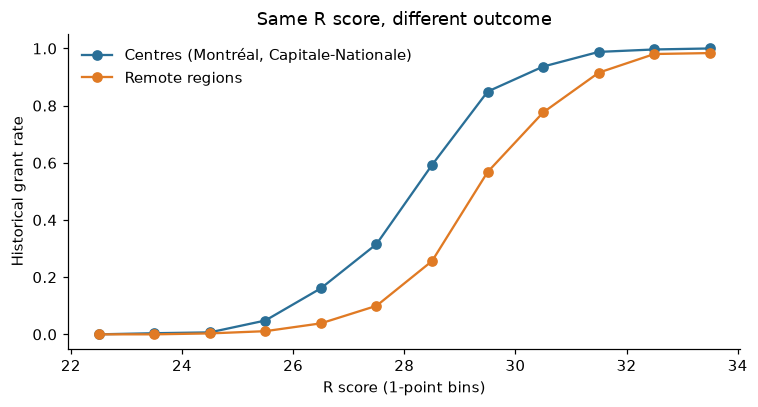

groupe,Centre,Eloignee
mid,,
26.5,0.161,0.038
27.5,0.316,0.100
28.5,0.593,0.256
29.5,0.849,0.568
30.5,0.937,0.776


In [3]:
bins = np.arange(22, 35, 1.0)
hist["R_bin"] = pd.cut(hist.cote_r_equivalent, bins)
curve = hist.groupby(["R_bin", "groupe"], observed=True).decision_octroi.agg(["mean", "size"]).reset_index()
curve["mid"] = curve.R_bin.apply(lambda iv: iv.mid).astype(float)

fig, ax = plt.subplots(figsize=(7, 3.8))
for g in (eq.CENTRE, eq.REMOTE):
    s = curve[(curve.groupe == g) & (curve["size"] >= 30)]
    ax.plot(s.mid, s["mean"], marker="o", color=COL[g], label=LABEL[g])
ax.set_xlabel("R score (1-point bins)")
ax.set_ylabel("Historical grant rate")
ax.set_title("Same R score, different outcome")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/audit_grant_rate_by_R.png", bbox_inches="tight"); plt.show()

display(curve.pivot(index="mid", columns="groupe", values="mean").loc[26.5:30.5])

At the same R score a remote applicant is much less likely to get an award. Between R = 28 and 29,
for example, the centre rate is more than twice the remote rate. The curves look like the same
S-curve shifted to the right by one to two R points.

**Decomposition.** We now split the 21-point gap into what profile differences explain and what
they do not. We fit a logistic model of the committee on merit features **plus** a remote indicator,
then ask: what would remote applicants' grant rate be if the indicator were switched off?

In [4]:
committee = eq.BiasAwareModel().fit(hist, hist.decision_octroi)
p_actual = 1 / (1 + np.exp(-committee.score(hist, 0.0)))
p_no_pen = 1 / (1 + np.exp(-committee.score(hist, 1.0)))
rem = hist.groupe == eq.REMOTE

# R-only counterfactual: remote applicants judged like centre applicants with the same R score.
r_only = LogisticRegression(max_iter=5000).fit(hist.loc[~rem, ["cote_r_equivalent"]], hist.decision_octroi[~rem])
p_r_only_remote = r_only.predict_proba(hist.loc[rem, ["cote_r_equivalent"]])[:, 1].mean()

centre_rate = hist.decision_octroi[~rem].mean()
remote_rate = hist.decision_octroi[rem].mean()
rows = [
    ("Observed gap", centre_rate - remote_rate),
    ("Gap if remote judged like centres with same R only", centre_rate - p_r_only_remote),
    ("Gap if remote judged without the penalty (all merit features)", centre_rate - p_no_pen[rem].mean()),
]
decomp = pd.DataFrame(rows, columns=["scenario", "gap"]).set_index("scenario")
display(decomp)
share_unexplained = 1 - decomp.gap.iloc[2] / decomp.gap.iloc[0]
print(f"Share of the observed gap explained by the regional penalty: {share_unexplained:.0%}")

,gap
scenario,
Observed gap,0.211
Gap if remote judged like centres with same R only,0.076
Gap if remote judged without the penalty (all merit features),0.036


Share of the observed gap explained by the regional penalty: 83%


Judging remote applicants like centre applicants with the same R score already cuts the gap from 21 to about 8 points.
With the penalty switched off and all merit features used, the gap almost disappears: under 4 points remain, and those
come from real profile differences (slightly lower R scores and lower family income in the remote
regions). So **most of the gap is not merit**.

## 3. The committee's decision rule

The committee model in `equialgo.BiasAwareModel` is a plain logistic regression. Before trusting its
penalty estimate we check three things: that it fits as well as a flexible model, that the penalty is
stable (bootstrap), and that it is the same in every remote region (region-level model).

In [5]:
print("Committee model coefficients (logits):")
display(committee.coef_.to_frame("coef"))
print(f"Regional penalty: {committee.penalty:.2f} logits = {committee.penalty_in_r_points:.2f} R points")

# Bootstrap the penalty.
rng = np.random.default_rng(0)
boot = []
for _ in range(200):
    idx = rng.integers(0, len(hist), len(hist))
    b = eq.BiasAwareModel().fit(hist.iloc[idx], hist.decision_octroi.iloc[idx])
    boot.append((b.penalty, b.penalty_in_r_points))
boot = np.array(boot)
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
print(f"95% bootstrap CI: {lo[0]:.2f} to {hi[0]:.2f} logits, {lo[1]:.2f} to {hi[1]:.2f} R points")

Committee model coefficients (logits):


,coef
cote_r,1.385
log_revenu,1.779
heures,0.202
distance_100km,0.109
eloignee,-2.165


Regional penalty: 2.17 logits = 1.56 R points


95% bootstrap CI: 1.89 to 2.40 logits, 1.39 to 1.73 R points


In [6]:
# Is a linear-logistic rule enough? Compare cross-validated fit with a gradient-boosting model.
X = eq.features(hist)
y = hist.decision_octroi
for name, mdl in [("logistic (5 features)", LogisticRegression(C=1e4, max_iter=10000)),
                  ("gradient boosting (5 features)", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05))]:
    p = cross_val_predict(mdl, X, y, cv=5, method="predict_proba")[:, 1]
    print(f"{name:<32} log-loss {log_loss(y, p):.4f}   accuracy {accuracy_score(y, p > .5):.4f}")

logistic (5 features)            log-loss 0.2589   accuracy 0.8876


gradient boosting (5 features)   log-loss 0.2873   accuracy 0.8772


In [7]:
# One dummy per region (Bas-Saint-Laurent is the reference) and per postal code inside regions.
Xr = eq.features(hist).drop(columns="eloignee")
Xr = pd.concat([Xr, pd.get_dummies(hist.region_administrative, drop_first=True).astype(int)], axis=1)
lr_reg = LogisticRegression(C=1e4, max_iter=10000).fit(Xr, y)
print("Region effects vs Bas-Saint-Laurent (logits):")
display(pd.Series(lr_reg.coef_[0], index=Xr.columns).iloc[4:].to_frame("coef"))

# Residuals by postal code after the committee model: does the postal code add anything?
hist["resid"] = y - 1 / (1 + np.exp(-committee.score(hist, 0.0)))
pc = hist.groupby(["region_administrative", "code_postal_3"]).resid.agg(["mean", "size"])
print(f"Largest |mean residual| by postal code: {pc['mean'].abs().max():.3f} (n per code ≈ {int(pc['size'].median())})")

# Does the penalty change with R? Interaction test.
Xi = eq.features(hist); Xi["R_x_remote"] = Xi.cote_r * Xi.eloignee
lr_int = LogisticRegression(C=1e4, max_iter=10000).fit(Xi, y)
print(f"R x remote interaction: {lr_int.coef_[0][-1]:+.3f} logits per R point (≈ 0 means a flat penalty)")
print("Programme of study and first-generation status, added to the model:")
Xp = pd.concat([eq.features(hist), pd.get_dummies(hist.programme_etudes, drop_first=True).astype(int),
                hist.premiere_generation_universitaire], axis=1)
display(pd.Series(LogisticRegression(C=1e4, max_iter=10000).fit(Xp, y).coef_[0], index=Xp.columns).iloc[5:].to_frame("coef"))

Region effects vs Bas-Saint-Laurent (logits):


,coef
Capitale-Nationale,2.172
Cote-Nord,-0.019
Gaspesie-Iles-de-la-Madeleine,0.102
Montreal,2.215


Largest |mean residual| by postal code: 0.031 (n per code ≈ 491)
R x remote interaction: +0.041 logits per R point (≈ 0 means a flat penalty)
Programme of study and first-generation status, added to the model:


,coef
Genie,0.055
Sante,0.065
Sciences,0.022
Sciences sociales,0.010
premiere_generation_universitaire,-0.052


What this tells us about the committee:

- The logistic rule fits **at least as well** as gradient boosting, so a simple additive rule is a fair
  description of how the committee decided.
- R score dominates. Income and hours worked also push decisions up; distance barely matters once region
  is in the model.
- The three remote regions have the **same** effect (≈ 0 vs Bas-Saint-Laurent), and both centres have the
  same positive effect of about +2.2 logits. That is a block-level penalty, not a region-by-region story.
- Postal code adds nothing once region is known. Program of study and first-generation status play no role.
- The penalty does not depend on the R score.

## 4. Proxy variables: why dropping the region column fails

If the other columns can tell where an applicant lives, any model trained on the biased labels can
rebuild the penalty from them. We measure how well each column predicts the remote indicator
(cross-validated AUC: 0.5 = no information, 1.0 = perfect).

,AUC for predicting remote
code_postal_3 (one-hot),1.000
all except region & postal code,0.998
distance_domicile_campus_km,0.997
heures_travail_semaine,0.803
revenu_familial_estime,0.678
premiere_generation_universitaire,0.585
programme_etudes (one-hot),0.549
cote_r_equivalent,0.532


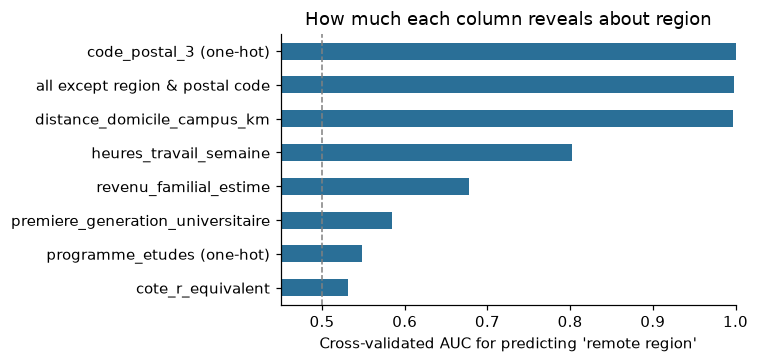

,remote,distance_domicile_campus_km,heures_travail_semaine,revenu_familial_estime,premiere_generation_universitaire,cote_r_equivalent
remote,1.00,0.82,0.52,-0.30,0.19,-0.11
distance_domicile_campus_km,0.82,1.00,0.43,-0.24,0.14,-0.08
heures_travail_semaine,0.52,0.43,1.00,-0.16,0.10,-0.05
revenu_familial_estime,-0.30,-0.24,-0.16,1.00,-0.06,0.03
premiere_generation_universitaire,0.19,0.14,0.10,-0.06,1.00,-0.02
cote_r_equivalent,-0.11,-0.08,-0.05,0.03,-0.02,1.00


In [8]:
target = (hist.groupe == eq.REMOTE).astype(int)
cols = {
    "distance_domicile_campus_km": hist[["distance_domicile_campus_km"]],
    "code_postal_3 (one-hot)": pd.get_dummies(hist.code_postal_3).astype(int),
    "heures_travail_semaine": hist[["heures_travail_semaine"]],
    "revenu_familial_estime": hist[["revenu_familial_estime"]],
    "premiere_generation_universitaire": hist[["premiere_generation_universitaire"]],
    "cote_r_equivalent": hist[["cote_r_equivalent"]],
    "programme_etudes (one-hot)": pd.get_dummies(hist.programme_etudes).astype(int),
    "all except region & postal code": hist[["distance_domicile_campus_km", "heures_travail_semaine",
                                              "revenu_familial_estime", "premiere_generation_universitaire",
                                              "cote_r_equivalent"]],
}
proxy = {}
for name, Xc in cols.items():
    p = cross_val_predict(HistGradientBoostingClassifier(max_iter=200), Xc, target, cv=5, method="predict_proba")[:, 1]
    proxy[name] = roc_auc_score(target, p)
proxy = pd.Series(proxy, name="AUC for predicting remote").sort_values(ascending=False)
display(proxy.to_frame())

fig, ax = plt.subplots(figsize=(7, 3.4))
proxy.iloc[::-1].plot.barh(ax=ax, color="#2a6f97")
ax.axvline(0.5, color="grey", lw=1, ls="--")
ax.set_xlim(0.45, 1.0); ax.set_xlabel("Cross-validated AUC for predicting 'remote region'")
ax.set_title("How much each column reveals about region")
plt.tight_layout(); plt.savefig("figures/audit_proxies.png", bbox_inches="tight"); plt.show()

display(hist.assign(remote=target)[["remote", "distance_domicile_campus_km", "heures_travail_semaine",
                                    "revenu_familial_estime", "premiere_generation_universitaire",
                                    "cote_r_equivalent"]].corr().round(2))

**Distance and postal code identify the region essentially perfectly**. Hours worked is a strong proxy
on its own and income a moderate one. Together, without region or postal code, the columns still
identify the region almost perfectly.

The next cell shows the mechanism directly. Fit the committee model **without** the remote indicator:
the penalty does not vanish, it moves into the proxy coefficients. Distance flips from a small positive
effect to a clearly negative one. A model "blind" to region still punishes the region, just through
distance.

In [9]:
X_full = eq.features(hist)
X_blind = X_full.drop(columns="eloignee")
lr_full = LogisticRegression(C=1e4, max_iter=10000).fit(X_full, y)
lr_blind = LogisticRegression(C=1e4, max_iter=10000).fit(X_blind, y)
display(pd.DataFrame({"with remote indicator": pd.Series(lr_full.coef_[0], X_full.columns),
                      "region-blind": pd.Series(lr_blind.coef_[0], X_blind.columns)}))

# Replicate the brief's test on the production random forest.
CAT = ["programme_etudes", "region_administrative", "code_postal_3"]
def encode(a, b):
    A = pd.get_dummies(a.drop(columns=["id_candidat", "decision_octroi", "groupe", "R_bin", "resid"], errors="ignore"), columns=CAT)
    B = pd.get_dummies(b.drop(columns=["id_candidat", "decision_octroi", "groupe", "R_bin", "resid"], errors="ignore"), columns=CAT).reindex(columns=A.columns, fill_value=0)
    return A, B

train, test = train_test_split(hist, test_size=0.3, random_state=42, stratify=hist.decision_octroi)
Xtr, Xte = encode(train, test)
g_test = test.groupe.to_numpy()
rows = []
for label, drop in [("all columns", ()), ("without region", ("region_administrative_",)),
                    ("without region and postal code", ("region_administrative_", "code_postal_3_")),
                    ("without region, postal code, distance", ("region_administrative_", "code_postal_3_", "distance_")),
                    ("R score + program only", ("region_administrative_", "code_postal_3_", "distance_", "heures_", "revenu_", "premiere_"))]:
    keep = [c for c in Xtr.columns if not c.startswith(drop)] if drop else list(Xtr.columns)
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(Xtr[keep], train.decision_octroi)
    p = rf.predict(Xte[keep])
    rows.append((label, accuracy_score(test.decision_octroi, p), eq.parity_gap(p, g_test)))
display(pd.DataFrame(rows, columns=["model", "accuracy vs committee", "parity gap"]).set_index("model"))

,with remote indicator,region-blind
cote_r,1.385,1.330
distance_100km,0.109,-0.499
eloignee,-2.165,NaN
heures,0.202,0.138
log_revenu,1.779,1.958


,accuracy vs committee,parity gap
model,,
all columns,0.881,0.188
without region,0.884,0.180
without region and postal code,0.879,0.173
"without region, postal code, distance",0.871,0.110
R score + program only,0.853,0.068


Dropping columns one after another barely moves the gap until almost everything is gone, and even a
model trained on the R score alone keeps a parity gap of about 0.07, because it is still trained to imitate biased
labels. **The problem is in the labels, not in the columns.** That is why our fix works on the label
side (section 5 and `model_corrige.ipynb`) instead of deleting features.

## 5. Auditing the production model against merit, not against the committee

The baseline notebook computes the true-positive rate against `decision_octroi`. That only checks that the
model copies the committee. To measure equal opportunity we need a notion of who *deserves* an award.

We do not have the jury's reference standard, so we build several stand-ins (`eq.merit_references`) and
check that conclusions hold for all of them. Each one grants 40% of applicants by ranking a merit score
that contains **no regional penalty**:

| Stand-in | Merit score |
|---|---|
| `committee_sans_penalite` | the committee's own criteria (section 3), penalty removed |
| `cote_r_seule` | R score only |
| `cote_r_heures` | R score with credit for hours worked |
| `cote_r_revenu_heures` | linear version of the committee's criteria |

We apply them to the 4,000 evaluation applicants, where the jury measures, and score the production
model exactly as the brief's last cell builds it (random forest on all columns, trained on all 10,000 files).

In [10]:
X_hist, X_cand = encode(hist, cand)
prod = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1)
prod.fit(X_hist, hist.decision_octroi)
p_prod = prod.predict(X_cand)
g_cand = cand.groupe.to_numpy()
print(f"Production model on the evaluation set: grant rate {p_prod.mean():.3f}, parity gap {eq.parity_gap(p_prod, g_cand):.3f}")

# Against the committee itself (what the baseline notebook measured), on the internal test split.
rf_test = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(Xtr, train.decision_octroi)
print(f"TPR gap against historical labels (test split): {eq.tpr_gap(test.decision_octroi, rf_test.predict(Xte), g_test):.3f}")

rows = []
for noise in (0.0, 1.0):
    refs = eq.merit_references(cand, committee, noise=noise, seed=1)
    for name, ref in refs.items():
        rows.append({"reference": name, "noise": noise,
                     "ref. rate centre": ref[g_cand == eq.CENTRE].mean(), "ref. rate remote": ref[g_cand == eq.REMOTE].mean(),
                     "EO gap (TPR centre - remote)": eq.tpr_gap(ref, p_prod, g_cand),
                     "agreement": (ref == p_prod).mean()})
audit = pd.DataFrame(rows).set_index(["reference", "noise"])
display(audit)

Production model on the evaluation set: grant rate 0.391, parity gap 0.190


TPR gap against historical labels (test split): 0.063


,,ref. rate centre,ref. rate remote,EO gap (TPR centre - remote),agreement
reference,noise,,,,
committee_sans_penalite,0.0,0.412,0.383,0.261,0.916
cote_r_seule,0.0,0.428,0.359,0.225,0.943
cote_r_heures,0.0,0.400,0.400,0.296,0.903
cote_r_revenu_heures,0.0,0.419,0.373,0.236,0.918
committee_sans_penalite,1.0,0.412,0.382,0.233,0.861
cote_r_seule,1.0,0.429,0.357,0.197,0.874
cote_r_heures,1.0,0.399,0.402,0.254,0.850
cote_r_revenu_heures,1.0,0.421,0.369,0.202,0.867


Against the committee's own labels the production model looks almost fair. Against any merit standard without
the penalty, deserving remote applicants are selected far less often: the equal-opportunity gap is about
**0.20 to 0.30** depending on the stand-in. The organisers report **0.270** against their hidden reference,
inside our range and close to our main stand-in. We take this as evidence that the hidden reference is a merit
ranking without the regional penalty, which is the assumption behind our fix.

Also note the reference rates: under a penalty-free merit ranking, remote applicants deserve awards at
roughly the same rate as centre applicants (a few points lower). The 21-point gap in the data is mostly bias.

## 5b. Inside the production model: where the penalty lives

Two checks on the production random forest itself, on the 4,000 evaluation applicants.

**SHAP attribution.** For each applicant, SHAP splits the predicted probability of an award into one contribution
per column. If the model were blind to location, the location columns would contribute about zero in both groups.

groupe,Centre: mean contribution (points of probability),Eloignee: mean contribution (points of probability)
region,3.0,-4.4
postal code,0.7,-1.0
distance,2.6,-4.4
hours worked,-0.4,1.1
family income,0.7,-1.2
R score,1.2,-5.4
program,-0.0,0.0
first generation,0.0,-0.0


Location columns (region + postal code + distance) move the predicted probability by +6.3% for centre applicants and -9.7% for remote applicants


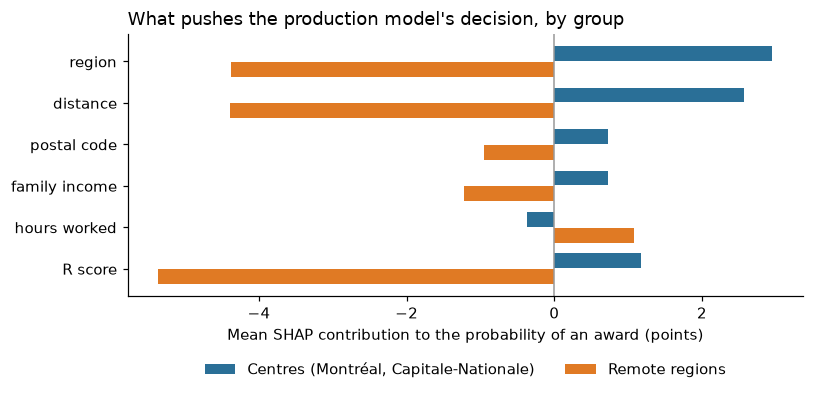

In [11]:
import shap

sample = np.random.default_rng(0).choice(len(X_cand), 600, replace=False)
sv = shap.TreeExplainer(prod).shap_values(X_cand.iloc[sample])
sv = sv[..., 1] if np.ndim(sv) == 3 else sv[1]          # contributions to P(award)
families = {"region": "region_administrative_", "postal code": "code_postal_3_", "distance": "distance_",
            "hours worked": "heures_", "family income": "revenu_", "R score": "cote_r_",
            "program": "programme_", "first generation": "premiere_"}
contrib = pd.DataFrame({name: sv[:, [i for i, c in enumerate(X_cand.columns) if c.startswith(prefix)]].sum(axis=1)
                        for name, prefix in families.items()})
contrib["groupe"] = g_cand[sample]
shap_by_group = contrib.groupby("groupe").mean().T
display((100 * shap_by_group).round(1).rename(columns=lambda c: f"{c}: mean contribution (points of probability)"))
location = shap_by_group.loc[["region", "postal code", "distance"]].sum()
print(f"Location columns (region + postal code + distance) move the predicted probability by "
      f"{location[eq.CENTRE]:+.1%} for centre applicants and {location[eq.REMOTE]:+.1%} for remote applicants")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
order = ["region", "distance", "postal code", "family income", "hours worked", "R score"]
y = np.arange(len(order))
for k, g in enumerate((eq.CENTRE, eq.REMOTE)):
    ax.barh(y + (k - 0.5) * 0.38, 100 * shap_by_group.loc[order, g], height=0.36, color=COL[g], label=LABEL[g])
ax.axvline(0, color="#999999", lw=1)
ax.set_yticks(y); ax.set_yticklabels(order); ax.invert_yaxis()
ax.set_xlabel("Mean SHAP contribution to the probability of an award (points)")
ax.set_title("What pushes the production model's decision, by group", loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.savefig("figures/audit_shap_location.png", bbox_inches="tight"); plt.show()

For remote applicants the region label and the distance each cost about 4 points of probability, and the postal
code about 1 more. Distance carries as much penalty as the region label itself, which is exactly why deleting the
label does not work. (The R-score contribution is also lower for remote applicants; part of that is their slightly
lower average R score, which is legitimate.)

**The move-to-Montréal test (counterfactual).** We take every remote applicant, keep everything about the
*student* (R score, hours worked, family income, program, first-generation status), and only change *where they
live*: region, postal code (H2X) and distance (centre median). How many decisions flip?

In [12]:
def relocate(df, region, postal_code=None, distance_km=None):
    moved = df.copy()
    moved["region_administrative"] = region
    if postal_code is not None:
        moved["code_postal_3"] = postal_code
    if distance_km is not None:
        moved["distance_domicile_campus_km"] = distance_km
    return moved

centre_km = hist.loc[hist.groupe == eq.CENTRE, "distance_domicile_campus_km"].median()
remote_km = hist.loc[hist.groupe == eq.REMOTE, "distance_domicile_campus_km"].median()
is_rem = g_cand == eq.REMOTE

# Our corrected model, for comparison: same 41% cutoff before and after the move.
final_score = committee.final_score(cand)
final_cut = np.sort(final_score)[::-1][int(round(eq.FINAL_RATE * len(cand))) - 1]

def flips(subset, moved, direction):
    before = prod.predict(encode(hist, subset)[1])
    after = prod.predict(encode(hist, moved)[1])
    fin_before = committee.final_score(subset) >= final_cut
    fin_after = committee.final_score(moved) >= final_cut
    if direction == "gain":
        return int(((before == 0) & (after == 1)).sum()), int((~fin_before & fin_after).sum())
    return int(((before == 1) & (after == 0)).sum()), int((fin_before & ~fin_after).sum())

rem_c, cen_c = cand[is_rem], cand[~is_rem]
tests = [
    ("Remote -> Montréal: region label only", rem_c, relocate(rem_c, "Montreal"), "gain"),
    ("Remote -> Montréal: label + postal code", rem_c, relocate(rem_c, "Montreal", "H2X"), "gain"),
    ("Remote -> Montréal: label + postal code + distance", rem_c, relocate(rem_c, "Montreal", "H2X", centre_km), "gain"),
    ("Centre -> Gaspésie: label + postal code + distance", cen_c,
     relocate(cen_c, "Gaspesie-Iles-de-la-Madeleine", "G4X", remote_km), "lose"),
]
rows = []
for label, subset, moved, direction in tests:
    n_prod, n_final = flips(subset, moved, direction)
    rows.append((label, len(subset), "refused -> granted" if direction == "gain" else "granted -> refused",
                 n_prod, n_prod / len(subset), n_final))
counterfactual = pd.DataFrame(rows, columns=["move", "applicants", "flip", "production model", "share", "our model"]).set_index("move")
display(counterfactual)

,applicants,flip,production model,share,our model
move,,,,,
Remote -> Montréal: region label only,1628,refused -> granted,79,0.049,0
Remote -> Montréal: label + postal code,1628,refused -> granted,107,0.066,0
Remote -> Montréal: label + postal code + distance,1628,refused -> granted,190,0.117,0
Centre -> Gaspésie: label + postal code + distance,2372,granted -> refused,297,0.125,0


**About one remote applicant in eight would be granted an award by the production model just by living in
Montréal**, with the same grades, hours and family income. Changing only the region label flips fewer than half of
them; the rest come through the postal code and distance. In the other direction, about one centre applicant in
eight would lose their award by moving to Gaspésie. Our corrected model flips none, by construction: where you live
does not enter its score.

## 6. A second channel: the income bonus

The committee model in section 3 gives a clear positive weight to family income, in both groups. A merit
scholarship has no reason to reward family wealth, and income is a regional proxy (section 4: remote families earn
less). So the income weight is a second way the committee disadvantaged remote applicants, separate from the
explicit penalty. We measure how much it matters.

In [13]:
inc = hist.groupby("groupe").revenu_familial_estime.median()
print(f"Median family income: centre {inc[eq.CENTRE]:,.0f} $, remote {inc[eq.REMOTE]:,.0f} $ "
      f"({1 - inc[eq.REMOTE] / inc[eq.CENTRE]:.0%} lower)")
print(f"Committee weight on log(income): {committee.coef_['log_revenu']:.2f} logits "
      f"= {committee.coef_['log_revenu'] / committee.coef_['cote_r']:.2f} R points per log-unit")
gap_inc = np.log(inc[eq.CENTRE] / inc[eq.REMOTE]) * committee.coef_["log_revenu"] / committee.coef_["cote_r"]
print(f"For the median applicants, the income term alone is worth {gap_inc:.2f} R points in favour of centres")

# Grant rates on the historical files under three versions of the committee rule, each at a 40% budget.
rows = []
for label, s in [("committee as it decided", committee.score(hist, 0.0)),
                 ("penalty removed", committee.score(hist, 1.0)),
                 ("penalty and income removed", committee.score(hist, 1.0, ("log_revenu",))),
                 ("penalty, income and distance removed", committee.score(hist, 1.0, eq.FINAL_DROP))]:
    p = eq.select_top(s, 0.40)
    r = eq.selection_rates(p, hist.groupe)
    rows.append((label, r[eq.CENTRE], r[eq.REMOTE], eq.parity_gap(p, hist.groupe)))
display(pd.DataFrame(rows, columns=["rule (40% budget)", "rate centre", "rate remote", "parity gap"]).set_index("rule (40% budget)"))

Median family income: centre 69,176 $, remote 51,562 $ (25% lower)
Committee weight on log(income): 1.78 logits = 1.28 R points per log-unit
For the median applicants, the income term alone is worth 0.38 R points in favour of centres


,rate centre,rate remote,parity gap
rule (40% budget),,,
committee as it decided,0.489,0.266,0.223
penalty removed,0.415,0.377,0.038
penalty and income removed,0.395,0.407,-0.012
"penalty, income and distance removed",0.403,0.396,0.006


Removing the penalty closes most of the gap. Removing the income bonus closes the rest: remote and centre
applicants then receive awards at about the same rate, because once wealth stops counting their merit profiles
(R score and hours worked) are close.

**External check with the HxBuddy indicative score.** The organisers' platform reports accuracy against the hidden
reference standard for each submission. We used 24 submissions as controlled experiments: each file changes one
ingredient of the score, all at a fixed grant rate. This does not show us the reference, only how close each file is.

In [14]:
# Indicative accuracy returned by HxBuddy for each submitted file (copied from the platform, 2026-10-03).
# Score = weights applied to R score (R), hours worked (h), log income (inc), distance (dist), first-generation (fg).
hxbuddy = pd.DataFrame([
    ("first submission: committee criteria, penalty removed", "R + inc + h + dist", "40%", 92.38),
    ("p01", "R only", "40%", 92.28),
    ("p02", "R + h", "40%", 94.63),
    ("p03", "R + inc", "40%", 90.08),
    ("p04", "R + h + dist", "40%", 94.38),
    ("p05", "R - inc + h + dist (need-based)", "40%", 91.73),
    ("p06", "R + inc + 2h + dist", "40%", 91.13),
    ("p07", "R + inc + h + dist + fg bonus", "40%", 91.98),
    ("r2_01", "R + 0.12 h", "40%", 94.33),
    ("r2_02", "R + 0.17 h", "40%", 94.53),
    ("r2_03", "R + 0.20 h", "40%", 94.03),
    ("r2_04 (final)", "R + 0.146 h", "41%", 94.68),
    ("r2_05", "R + 0.146 h", "42%", 94.43),
    ("r2_06", "R + 0.16 h + 0.05 inc", "41%", 94.68),
    ("r3_01", "R + 0.146 h + STEM program bonus", "41%", 94.23),
    ("r3_03", "R + 0.146 h", "40.5%", 94.58),
    ("r3_04", "R + 0.95 sqrt(h) (diminishing returns)", "41%", 94.43),
    ("r3_05", "R + 0.20 max(h - 8, 0) (only long hours)", "41%", 94.03),
    ("r4_01", "R + 0.135 h", "41%", 94.53),
    ("r4_02", "R + 0.158 h", "41%", 94.63),
    ("r5_01", "R + 0.150 h", "40.75%", 94.58),
    ("r5_02", "R + 0.148 h", "41.25%", 94.58),
    ("r5_03", "R + 0.158 h", "41.25%", 94.63),
    ("r5_04", "R + 0.140 h", "41.5%", 94.53),
    ("r5_05", "R + 0.140 h", "40.75%", 94.48),
], columns=["file", "merit score", "grant rate", "HxBuddy accuracy (%)"]).set_index("file")
display(hxbuddy)

,merit score,grant rate,HxBuddy accuracy (%)
file,,,
"first submission: committee criteria, penalty removed",R + inc + h + dist,40%,92.38
p01,R only,40%,92.28
p02,R + h,40%,94.63
p03,R + inc,40%,90.08
p04,R + h + dist,40%,94.38
p05,R - inc + h + dist (need-based),40%,91.73
p06,R + inc + 2h + dist,40%,91.13
p07,R + inc + h + dist + fg bonus,40%,91.98
r2_01,R + 0.12 h,40%,94.33


What the experiments say:

- **Income is not merit.** Adding income always lowers agreement: R + income (p03) scores 90.08 against 92.28 for
  R alone, and our first submission scored 92.38 with income against 94.38 without it (p04). Reversing the sign
  (need-based, p05) does not help either. The reference ignores income.
- **Hours worked are merit.** R + hours beats R alone by more than 2 points. The best hours weight is about 0.146 R
  points per weekly hour, which is exactly the committee's own ratio (section 3). The committee valued work hours
  correctly; it added the penalty and the income bonus on top.
- **Distance and first-generation status add nothing.**
- **Program of study does not count, and hours count linearly.** A program bonus (r3_01) and both curved
  versions of hours (r3_04, r3_05) score lower.
- **The committee's hours weight is the peak.** At a 41% grant rate, 0.135 scores 94.53, 0.146 scores 94.68 and
  0.158 scores 94.63 (round 4). Five more nearby variants (weights 0.140 to 0.158, rates 40.75% to 41.5%) all scored
  between 94.48 and 94.63 (round 5). The weight we took from the committee model was never improved by tuning.
- **Diminishing returns.** The second round moved accuracy by 0.05 points; the third, fourth and fifth found nothing better. The reference appears to contain variation
  that the columns cannot explain, so we stopped tuning there rather than fit the leaderboard's noise.

## 6b. Who was hurt most, and how sure are we?

The two-group view can hide a subgroup that is hurt more than average. We cross region with family income,
first-generation status and program, on the 4,000 evaluation applicants. Merit reference: R score + credit for
hours worked (`cote_r_heures`, the stand-in closest to the hidden reference), granting 41%. We show the
production model and, for comparison, our corrected model.

In [15]:
final_dec = eq.select_top(committee.final_score(cand), eq.FINAL_RATE)
merit = eq.merit_references(cand, committee, rate=eq.FINAL_RATE)["cote_r_heures"]
dims = {
    "income quartile": pd.qcut(cand.revenu_familial_estime, 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"]).astype(str).to_numpy(),
    "first generation": np.where(cand.premiere_generation_universitaire == 1, "first-gen", "not first-gen"),
    "program": cand.programme_etudes.to_numpy(),
}
rows = []
for dim, levels in dims.items():
    for level in sorted(set(levels)):
        for g in (eq.CENTRE, eq.REMOTE):
            m = (levels == level) & (g_cand == g)
            deserving = m & (merit == 1)
            rows.append({"dimension": dim, "level": level, "group": g, "n": int(m.sum()),
                         "grant rate, production": p_prod[m].mean(), "grant rate, ours": final_dec[m].mean(),
                         "TPR, production": p_prod[deserving].mean(), "TPR, ours": final_dec[deserving].mean()})
inter = pd.DataFrame(rows).set_index(["dimension", "level", "group"])
display(inter)
worst = inter["TPR, production"].idxmin()
print(f"Worst-served subgroup under the production model: {worst} -> TPR {inter.loc[worst, 'TPR, production']:.3f} "
      f"(ours: {inter.loc[worst, 'TPR, ours']:.3f})")
print(f"Range of grant rates across all subgroups: production {inter['grant rate, production'].min():.1%} to "
      f"{inter['grant rate, production'].max():.1%}, ours {inter['grant rate, ours'].min():.1%} to {inter['grant rate, ours'].max():.1%}")

n  grant rate, production  \
dimension        level             group                                    
income quartile  Q1 lowest         Centre     374                   0.436   
                                   Eloignee   626                   0.240   
                 Q2                Centre     568                   0.423   
                                   Eloignee   432                   0.280   
                 Q3                Centre     659                   0.467   
                                   Eloignee   341                   0.302   
                 Q4 highest        Centre     771                   0.518   
                                   Eloignee   229                   0.341   
first generation first-gen         Centre     634                   0.457   
                                   Eloignee   735                   0.273   
                 not first-gen     Centre    1738                   0.472   
                                   Eloignee   893                   0.281   
program          Arts et lettres   Centre     380                   0.445   
                                   Eloignee   338                   0.246   
                 Genie             Centre     611                   0.466   
                                   Eloignee   375                   0.264   
                 Sante             Centre     359                   0.513   
                                   Eloignee   279                   0.297   
                 Sciences          Centre     532                   0.461   
                                   Eloignee   306                   0.294   
                 Sciences sociales Centre     490                   0.463   
                                   Eloignee   330                   0.294   

                                             grant rate, ours  \
dimension        level             group                        
income quartile  Q1 lowest         Centre               0.406   
                                   Eloignee             0.417   
                 Q2                Centre               0.389   
                                   Eloignee             0.391   
                 Q3                Centre               0.416   
                                   Eloignee             0.405   
                 Q4 highest        Centre               0.420   
                                   Eloignee             0.441   
first generation first-gen         Centre               0.416   
                                   Eloignee             0.405   
                 not first-gen     Centre               0.407   
                                   Eloignee             0.415   
program          Arts et lettres   Centre               0.403   
                                   Eloignee             0.388   
                 Genie             Centre               0.380   
                                   Eloignee             0.421   
                 Sante             Centre               0.443   
                                   Eloignee             0.427   
                 Sciences          Centre               0.400   
                                   Eloignee             0.428   
                 Sciences sociales Centre               0.437   
                                   Eloignee             0.394   

                                             TPR, production  TPR, ours  
dimension        level             group                                 
income quartile  Q1 lowest         Centre              0.980      0.993  
                                   Eloignee            0.575      0.996  
                 Q2                Centre              0.973      1.000  
                                   Eloignee            0.716      1.000  
                 Q3                Centre              0.985      1.000  
                                   Eloignee            0.737      1.000  
                 Q4 highest        Centre     

Worst-served subgroup under the production model: ('income quartile', 'Q1 lowest', 'Eloignee') -> TPR 0.575 (ours: 0.996)
Range of grant rates across all subgroups: production 24.0% to 51.8%, ours 38.0% to 44.3%


In [16]:
# Bootstrap 95% confidence intervals (1,000 resamples of the 4,000 applicants).
rng = np.random.default_rng(0)
n = len(cand)
rows = []
for name, pred in [("production model", p_prod), ("our model", final_dec)]:
    par, eo = [], []
    for _ in range(1000):
        i = rng.integers(0, n, n)
        par.append(eq.parity_gap(pred[i], g_cand[i]))
        eo.append(eq.tpr_gap(merit[i], pred[i], g_cand[i]))
    rows.append((name, eq.parity_gap(pred, g_cand), *np.percentile(par, [2.5, 97.5]),
                 eq.tpr_gap(merit, pred, g_cand), *np.percentile(eo, [2.5, 97.5])))
display(pd.DataFrame(rows, columns=["model", "parity gap", "CI low", "CI high",
                                    "EO gap (vs R + hours)", "EO CI low", "EO CI high"]).set_index("model").round(3))

,parity gap,CI low,CI high,EO gap (vs R + hours),EO CI low,EO CI high
model,,,,,,
production model,0.190,0.161,0.218,0.311,0.275,0.348
our model,-0.002,-0.033,0.030,0.000,-0.003,0.005


- **The most-penalised subgroup is low-income remote students.** Under the production model, about four in ten
  of the deserving ones are refused (TPR ≈ 0.58), while low-income centre students are almost never refused.
  The penalty and the income bonus stack on the same students.
- After correction, every subgroup is granted between roughly 38% and 44%, and deserving applicants are selected
  at the same rate (TPR ≥ 0.99) in every cell, so the fix does not create a new disadvantaged subgroup.
- The production model's gaps are far outside sampling noise (parity gap 0.19, 95% CI about 0.16 to 0.22).
  Ours are indistinguishable from zero. The EO gap of our model is near zero partly by construction, because this
  merit reference uses the same formula; the HxBuddy result in section 6 is the independent check.

## 7. Which fairness metric, and why

We choose **equal opportunity**: among applicants who deserve an award, the share who get one should not
depend on region (TPR parity). We report demographic parity as a secondary indicator.

Reasons:

- **It matches the purpose of a merit scholarship.** The institution wants to fund the best applicants.
  Equal opportunity says *the deserving remote student has the same chance as the deserving Montréal student*.
  That is the promise that was broken here.
- **Demographic parity would over-correct.** Remote applicants have slightly weaker profiles on average
  (lower R score, lower income). Forcing equal grant rates would select some less-deserving remote applicants
  over more-deserving centre applicants, and it can be met by a model that is still wrong about *who* in each
  group deserves the award. The brief also notes the two cannot both hold when profiles differ.
- **It is what the jury scores.** The automated equity points measure the share of the 0.270 equal-opportunity
  gap that is closed.
- **The weakness, stated honestly:** equal opportunity needs a "deserving" label, and the only label we have
  is biased. A TPR computed on `decision_octroi` would certify the bias (section 5). So we measure it against
  several penalty-free merit references, and we treat that as an assumption to monitor in production, not a
  fact.

## 8. Limitations of this diagnosis

- The reference standards are **our constructions**. The match with the published 0.270 supports the main
  one but does not prove it. If true merit includes something we cannot see, our numbers are off.
- The committee model is estimated from 10,000 synthetic files. With real data, part of a group effect could
  come from an omitted legitimate variable (for example, program quality differences between CEGEPs). Here we
  find no such variable: program, first-generation status and postal code add nothing.
- Two groups hide variation. We checked the five regions separately and they collapse into two blocks, but in
  production the audit must also run at region level and on intersections (region × income, region ×
  first-generation).
- Removing income is supported by two arguments: a merit scholarship should not reward family wealth, and the
  HxBuddy feedback agrees. The second argument uses 24 leaderboard submissions, which is a small form of tuning
  on the evaluation set; we disclose it and kept the experiments to a handful of interpretable choices.
  Whether a *need-based* component should be added is a policy question for the institution (`GOVERNANCE.md`).